# 05 · Return-risk model + return analytics

**Business problem.** ~2.5% of sold lines come back (EGP millions in refunds + courier fees). Two things help:
1. **Which lines are most likely to be returned?** → flag them for a proactive step (size confirmation call, extra QA before packing).
2. **Where do returns concentrate?** (category × size × reason) → fix the root cause (size guide, product quality, picking errors).

**Honesty first.** In many datasets, returns are close to random. So this notebook includes a **signal check**: the model is compared with a
trivial baseline (average return rate per channel × category). If the model does not clearly beat it, *do not automate decisions with it* – use the analytics tables instead.

**Method.** HistGradientBoosting classifier on order-line features (category, size, channel, discount, quantity, price, customer age…),
**time-based split** and a **45-day censoring buffer** (very recent orders have not had time to be returned yet, so they are excluded from labels).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the `cottonil` package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cottonil import config as cfg
from cottonil.data_io import load_table, load_sales_lines, load_product_master, week_start, quick_profile
from cottonil.plotting import setup, NAVY, TEAL, ORANGE, RED, PALETTE
setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR = cfg.find_data_dir()
SOURCE = cfg.data_source(DATA_DIR)
print(f"Data folder : {DATA_DIR}")
print(f"Data source : {SOURCE.upper()}" + ("   <-- synthetic test data; retrain on real data before trusting any number" if SOURCE == "synthetic" else ""))

Data folder : D:\HVIA Internship\task 2\cottonil-ai\COTTONIL_Data
Data source : REAL


In [2]:
from cottonil import returns as RT
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
lines = load_sales_lines()
orders_c = load_table("customers")[["customer_id", "age_band", "customer_segment"]]
ret = load_table("sales_returns")
lines = lines.merge(orders_c, on="customer_id", how="left")
lines["age_band"] = lines["age_band"].astype(object).fillna("unknown"); lines["customer_segment"] = lines["customer_segment"].astype(object).fillna("unknown")
lines["y"] = lines.sales_line_id.isin(ret.sales_line_id).astype(int)
last = lines.order_date.max(); label_end = last - pd.Timedelta(days=45)
lab = lines[lines.order_date <= label_end].copy()
print(f"{len(lab):,} labelled lines | return rate {lab.y.mean():.2%} | labels up to {label_end.date()} (last 45 days excluded)")
lab.groupby("sales_channel", observed=True).y.mean().round(4).to_frame("return rate")

1,114,397 labelled lines | return rate 2.50% | labels up to 2026-09-03 (last 45 days excluded)


,return rate
sales_channel,
E-commerce,0.0250
Retail POS,0.0250
Wholesale / reseller,0.0255


## 1 · Where do returns concentrate? (analytics – no ML needed)

In [3]:
rx = ret.merge(lines[["sales_line_id", "category", "size", "sales_channel"]], on="sales_line_id", how="left")
sold = lines.groupby(["category", "size"], observed=True).agg(lines=("sales_line_id", "size"), units=("quantity", "sum")).reset_index()
sold[["category", "size"]] = sold[["category", "size"]].astype(str)
rr = rx.assign(category=rx.category.astype(str), size=rx["size"].astype(str)).pivot_table(index=["category", "size"], columns="reason", values="return_id", aggfunc="count", fill_value=0).reset_index()
rr = sold.merge(rr, on=["category", "size"], how="left").fillna(0)
reason_cols = [c for c in rr.columns if c not in ("category", "size", "lines", "units")]
rr["returns"] = rr[reason_cols].sum(axis=1); rr["return_rate"] = rr.returns / rr.lines
cfg.save_serving("return_rates", rr.round(5))
by_cat = rr.groupby("category").agg(lines=("lines", "sum"), returns=("returns", "sum"), **{c: (c, "sum") for c in reason_cols}); by_cat["return_rate"] = by_cat.returns / by_cat.lines
by_cat.sort_values("return_rate", ascending=False).round(4).head(8)

,lines,returns,Defect claim,Exchange,Other,Size issue,Wrong item,return_rate
category,,,,,,,,
Girls underwear,12308,321,71,62,59,71,58,0.0261
Accessories,8324,216,43,46,37,51,39,0.0259
Women bras,49259,1277,242,244,256,273,262,0.0259
Men bottoms,24860,639,120,132,135,132,120,0.0257
Men tops,148689,3813,786,774,756,796,701,0.0256
Women underwear,12476,319,74,58,65,68,54,0.0256
Women tops,115011,2924,565,603,604,594,558,0.0254
Men underwear,61781,1557,319,295,304,326,313,0.0252


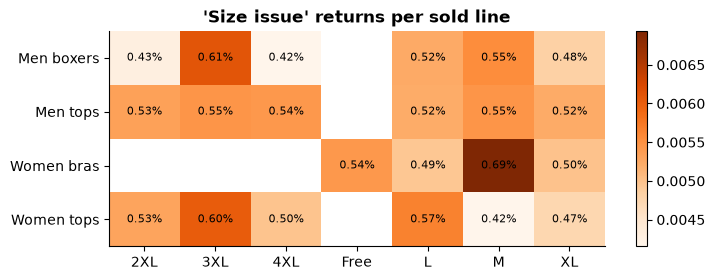

In [4]:
# Size-issue returns by size within apparel categories: is any size systematically wrong?
if "Size issue" in rr.columns:
    ap = rr[rr.category.isin(["Men boxers", "Men tops", "Women tops", "Women bras"])].copy(); ap["size_issue_rate"] = ap["Size issue"] / ap.lines
    piv = ap.pivot(index="category", columns="size", values="size_issue_rate")
    fig, ax = plt.subplots(figsize=(8, 2.8)); im = ax.imshow(piv.values, cmap="Oranges", aspect="auto")
    ax.set_xticks(range(len(piv.columns)), piv.columns); ax.set_yticks(range(len(piv.index)), piv.index); ax.grid(False)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]; ax.text(j, i, "" if np.isnan(v) else f"{v:.2%}", ha="center", va="center", fontsize=8)
    ax.set_title("'Size issue' returns per sold line"); plt.colorbar(im); plt.show()

## 2 · Predict return risk per line

In [5]:
tr_end, val_end = label_end - pd.Timedelta(days=300), label_end - pd.Timedelta(days=120)
tr, va, te = lab[lab.order_date <= tr_end], lab[(lab.order_date > tr_end) & (lab.order_date <= val_end)], lab[lab.order_date > val_end]
maps = RT.fit_maps(tr)
Xtr, Xva, Xte = (RT.encode(d, maps) for d in (tr, va, te))
print(f"train {len(tr):,} ({tr.y.mean():.2%}) | val {len(va):,} ({va.y.mean():.2%}) | test {len(te):,} ({te.y.mean():.2%})")
cat_idx = [RT.FEATURES.index(c) for c in RT.CAT_COLS]
clf = HistGradientBoostingClassifier(learning_rate=0.06, max_iter=400, max_leaf_nodes=20, min_samples_leaf=200, l2_regularization=5.0,
                                     categorical_features=cat_idx, early_stopping=False, random_state=42).fit(Xtr, tr.y)
from sklearn.metrics import log_loss
ll = [log_loss(va.y, np.clip(p, 1e-6, 1 - 1e-6)) for p in clf.staged_predict_proba(Xva)]
best = int(np.argmin(ll)) + 1; print("best #trees on validation:", best)
model = HistGradientBoostingClassifier(**{**clf.get_params(), "max_iter": best}).fit(Xtr, tr.y)

train 938,268 (2.50%) | val 108,624 (2.56%) | test 67,505 (2.48%)


best #trees on validation: 52


In [6]:
# baseline = average return rate of (channel x category) from the training window
key = ["sales_channel", "category"]
rate = tr.groupby(key, observed=True).y.mean().rename("p").reset_index()
for c in key: rate[c] = rate[c].astype(str)
tmp = te[key].astype(str).merge(rate, on=key, how="left"); p_base = tmp.p.fillna(tr.y.mean()).values
p_te = model.predict_proba(Xte)[:, 1]; y = te.y.values
def lift(y, p, frac):
    k = max(1, int(len(y) * frac)); idx = np.argsort(-p)[:k]; return float(y[idx].mean() / y.mean())
def capture(y, p, frac):
    k = max(1, int(len(y) * frac)); idx = np.argsort(-p)[:k]; return float(y[idx].sum() / y.sum())
tab = pd.DataFrame({n: {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p),
                        "lift top 5%": lift(y, p, .05), "returns captured in top 10%": capture(y, p, .10)}
                    for n, p in {"HistGB model": p_te, "baseline (channel x category rate)": p_base}.items()}).T
print(f"test return rate: {y.mean():.2%}")
tab.round(4)

test return rate: 2.48%


,ROC-AUC,PR-AUC,Brier,lift top 5%,returns captured in top 10%
HistGB model,0.6363,0.0420,0.0240,2.4375,0.2210
baseline (channel x category rate),0.4991,0.0251,0.0242,1.1590,0.1075


SIGNAL CHECK -> MODEST EXTRA SIGNAL - usable to prioritise manual checks (top 5-10% of lines), not for hard rules. (AUC gain over baseline +0.137)


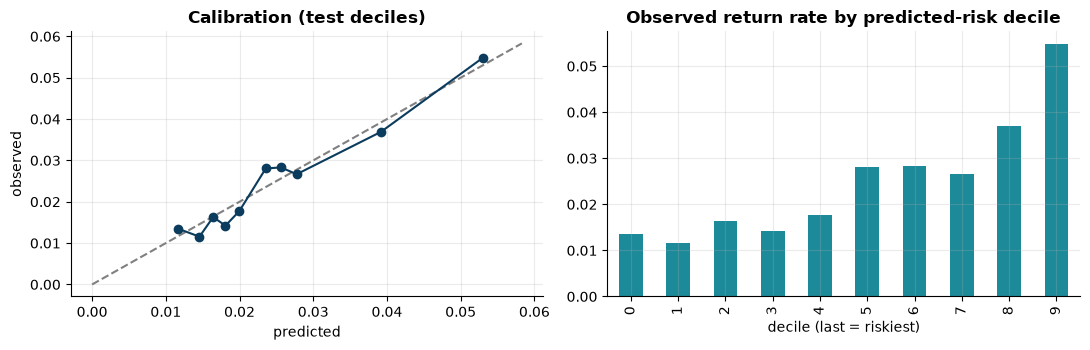

In [7]:
auc_gain = tab.loc["HistGB model", "ROC-AUC"] - tab.loc["baseline (channel x category rate)", "ROC-AUC"]
auc_m = tab.loc["HistGB model", "ROC-AUC"]
if auc_m < 0.55:
    verdict = "NO USABLE SIGNAL - returns look close to random given these features. Use the analytics tables only; do NOT automate decisions."
elif auc_gain < 0.01:
    verdict = ("SIGNAL IS SIMPLE - returns are predictable, but only through channel x category rates; the ML model adds nothing over that table. "
               "Use the baseline rate table (shown in the app) rather than a black box.")
elif auc_m < 0.65:
    verdict = "MODEST EXTRA SIGNAL - usable to prioritise manual checks (top 5-10% of lines), not for hard rules."
else:
    verdict = "USEFUL SIGNAL - suitable for risk-based interventions (confirm size, extra QA) on the top-risk lines."
print("SIGNAL CHECK ->", verdict, f"(AUC gain over baseline {auc_gain:+.3f})")
bins = pd.qcut(p_te, 10, duplicates="drop"); cal = pd.DataFrame({"p": p_te, "y": y}).groupby(bins, observed=True).mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot([0, cal.p.max() * 1.1], [0, cal.p.max() * 1.1], "--", color="grey"); ax[0].plot(cal.p, cal.y, "o-", color=NAVY); ax[0].set_title("Calibration (test deciles)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed")
cal.y.reset_index(drop=True).plot.bar(ax=ax[1], color=TEAL); ax[1].set_title("Observed return rate by predicted-risk decile"); ax[1].set_xlabel("decile (last = riskiest)")
plt.tight_layout(); plt.show()

## 3 · Refit on all labelled data and save

In [8]:
Xall = RT.encode(lab, maps)
final = HistGradientBoostingClassifier(**{**clf.get_params(), "max_iter": best}).fit(Xall, lab.y)
thr_top5 = float(np.quantile(final.predict_proba(RT.encode(lab.sample(min(200000, len(lab)), random_state=0), maps))[:, 1], .95))
cfg.save_serving("return_baseline_rates", rate.round(5))
cfg.save_model("return_risk", {"model": final, "maps": maps, "features": RT.FEATURES, "cat_idx": cat_idx, "base_rate": float(lab.y.mean()),
                               "top5_threshold": thr_top5, "verdict": verdict, "data_source": SOURCE})
cfg.save_metrics("05_return_risk", {"test_return_rate": float(y.mean()), "model": tab.loc["HistGB model"].round(4).to_dict(),
                                    "baseline": tab.loc["baseline (channel x category rate)"].round(4).to_dict(), "auc_gain": float(auc_gain),
                                    "verdict": verdict, "top5_threshold": thr_top5, "refunds_egp": float(ret.refund_amount_EGP.sum()),
                                    "returns": int(len(ret))}, DATA_DIR)
# sanity: the saved artefact scores a single hand-built line
demo = lab.sample(1, random_state=1)
print("example line risk:", float(final.predict_proba(RT.encode(demo, maps))[0, 1]), "| base rate", round(lab.y.mean(), 4), "| actual:", int(demo.y.iloc[0]))

example line risk: 0.016741579883952275 | base rate 0.025 | actual: 1


## Takeaways
* Read the **SIGNAL CHECK** line above before using the model; the verdict is computed, not hard-coded.
* Whatever the verdict, the analytics tables (`return_rates`) show *where* returns happen so the business can fix causes (size charts, QA, pick accuracy).
* Reason codes in this data are close to uniform – to reduce **wrong-item** returns the real fix is process (barcode scan at packing), which no model replaces.